**NAME:** <YOUR NAME>
**PRN:** <YOUR PRN>
**BATCH:** <YOUR BATCH>

**PRACTICAL ASSIGNMENT 2**
**PROBLEM SOLVING THROUGH SEARCH — Performance Evaluation of Uninformed, Informed, Local Search and Constraint Satisfaction Algorithms**

**Case Study: The 8-Queens Problem**

# AIM

To implement and evaluate the performance of different problem-solving-through-search techniques on the **8-Queens problem**, and to compare them on:

* whether a solution is found (completeness / success rate),
* number of nodes expanded (or states evaluated),
* memory used (peak number of states stored),
* execution time,
* solution quality (optimality) and scalability as the board size N grows.

### Algorithms implemented

| Category | Algorithms |
|---|---|
| Uninformed search | Depth First Search (DFS), Breadth First Search (BFS), Depth Limited Search (DLS), Iterative Deepening Search (IDS) |
| Informed search | A\* Search, Greedy Best First Search |
| Local search | Hill Climbing (steepest ascent, with sideways moves, with random restarts), Genetic Algorithm |
| Constraint Satisfaction | Backtracking, Backtracking + Forward Checking, + MRV heuristic, MAC (AC-3 constraint propagation) |

# PROBLEM STATEMENT

Place **N queens** on an N x N chess board so that **no two queens attack each other**, i.e. no two queens share the same row, the same column or the same diagonal.

The same problem is formulated in three different ways, because each family of algorithms needs a different view of it:

**1. Incremental state-space formulation (used by uninformed and informed search)**

* **State:** a partial placement, one queen in each of the first *k* rows. Stored as a tuple of column numbers, e.g. `(0, 4, 7)`
* **Initial state:** the empty board `()`
* **Actions:** put a queen in the next row, in any column that is not attacked by the queens already placed
* **Goal state:** N queens placed (`len(state) == N`)
* **Path cost:** 1 per queen placed (so every solution costs exactly N, which means every solution is optimal)

**2. Complete-state formulation (used by local search)**

* **State:** all N queens on the board, one per column, e.g. `[3, 1, 6, 2, 5, 7, 4, 0]`
* **Actions:** move one queen to another row of its column (N x (N-1) = 56 neighbours)
* **Objective:** minimise `h` = number of pairs of queens attacking each other (`h = 0` is a solution)

**3. Constraint Satisfaction formulation (used by CSP solvers)**

* **Variables:** Q0 ... Q(N-1), one per row
* **Domains:** column {0 ... N-1}
* **Constraints (binary):** for every pair i != j: `Qi != Qj` and `|Qi - Qj| != |i - j|`

# COMMON UTILITIES

Helper functions shared by all algorithms: attack test, successor generation, timeout guard and a board printer.

In [1]:
import time, random, heapq, itertools
from collections import deque
import pandas as pd
import matplotlib.pyplot as plt

N = 8

# ---------- incremental formulation helpers ----------
def safe(state, col):
    row = len(state)
    for r, c in enumerate(state):
        if c == col or abs(c - col) == row - r:
            return False
    return True

def successors(state, n):
    return [state + (c,) for c in range(n) if safe(state, c)]

def row_free_counts(state, n):
    # for every still-empty row: how many squares are not attacked
    counts = []
    for r in range(len(state), n):
        cnt = 0
        for c in range(n):
            if all(c != qc and abs(c - qc) != r - qr for qr, qc in enumerate(state)):
                cnt += 1
        counts.append(cnt)
    return counts

def dead_end(state, n):
    # some empty row has no free square -> this state can never be completed
    return any(c == 0 for c in row_free_counts(state, n))

# ---------- complete-state helper (local search) ----------
def conflicts(st):
    n = len(st)
    return sum(1 for i in range(n) for j in range(i + 1, n)
               if st[i] == st[j] or abs(st[i] - st[j]) == j - i)

# ---------- timeout guard so that slow algorithms do not hang the notebook ----------
class Timeout(Exception):
    pass

DEADLINE = None
def tick():
    if DEADLINE is not None and time.perf_counter() > DEADLINE:
        raise Timeout()

def run(algo, n=N, tl=10, **kw):
    global DEADLINE
    DEADLINE = time.perf_counter() + tl
    try:
        return algo(n, **kw)
    except Timeout:
        return dict(solution=None, nodes=None, peak=None, time=None, timeout=True)
    finally:
        DEADLINE = None

def pack(sol, nodes, peak, t0, **extra):
    d = dict(solution=sol, nodes=nodes, peak=peak, time=time.perf_counter() - t0)
    d.update(extra)
    return d

def show_board(sol):
    n = len(sol)
    for r in range(n):
        print(' '.join('Q' if sol[r] == c else '.' for c in range(n)))

print("Utilities ready. Board size N =", N)
print("Successors of the empty board :", successors((), 4))
print("Successors of (1,) on N=4     :", successors((1,), 4))

Utilities ready. Board size N = 8
Successors of the empty board : [(0,), (1,), (2,), (3,)]
Successors of (1,) on N=4     : [(1, 3)]


# 1. UNINFORMED SEARCH

Uninformed (blind) search uses only the problem definition. It has **no idea how close a state is to the goal**.

The search tree here has depth N (one queen per level) and a branching factor of at most N.
Because a queen is only ever placed on a safe square, no invalid state is ever generated, and since each state is a distinct sequence, no "visited" set is needed.

## 1.1 Depth First Search (DFS)

Expands the deepest node first using a **stack (LIFO)**. Memory is small (only the current branch and its siblings are stored), but it is **not guaranteed to be optimal** in general.

In [2]:
def dfs(n=N):
    t0 = time.perf_counter()
    stack = [()]
    nodes, peak = 0, 1
    while stack:
        s = stack.pop()
        nodes += 1
        if nodes & 255 == 0: tick()
        if len(s) == n:
            return pack(s, nodes, peak, t0)
        stack.extend(reversed(successors(s, n)))      # reversed -> leftmost column explored first
        peak = max(peak, len(stack))
    return pack(None, nodes, peak, t0)

r = run(dfs)
print("DFS solution   :", r['solution'])
print("Nodes expanded :", r['nodes'])
print("Peak stack size:", r['peak'])
print("Time (ms)      : %.3f" % (r['time'] * 1000))
show_board(r['solution'])

DFS solution   : (0, 4, 7, 5, 2, 6, 1, 3)
Nodes expanded : 114
Peak stack size: 19
Time (ms)      : 0.418
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


**Output explanation:** DFS dives down one branch at a time and backtracks when a row has no safe square. It reaches the first solution after expanding relatively few nodes and keeps only a small stack in memory. Every solution has the same cost N, so the solution found is optimal for this problem, although in general DFS gives no such guarantee.

## 1.2 Breadth First Search (BFS)

Expands nodes **level by level** using a **queue (FIFO)**. It is complete and finds the shallowest goal, but must store a whole level of the tree in memory.

In [3]:
def bfs(n=N):
    t0 = time.perf_counter()
    q = deque([()])
    nodes, peak = 0, 1
    while q:
        s = q.popleft()
        nodes += 1
        if nodes & 255 == 0: tick()
        if len(s) == n:
            return pack(s, nodes, peak, t0)
        q.extend(successors(s, n))
        peak = max(peak, len(q))
    return pack(None, nodes, peak, t0)

r = run(bfs)
print("BFS solution   :", r['solution'])
print("Nodes expanded :", r['nodes'])
print("Peak queue size:", r['peak'])
print("Time (ms)      : %.3f" % (r['time'] * 1000))
show_board(r['solution'])

BFS solution   : (0, 4, 7, 5, 2, 6, 1, 3)
Nodes expanded : 1966
Peak queue size: 573
Time (ms)      : 7.363
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


**Output explanation:** All solutions lie at the same depth N, so BFS has to finish every shallower level before it can reach any goal. It therefore expands far more nodes than DFS and holds a very large frontier (peak queue size) in memory. This is the classic time/memory weakness of BFS.

## 1.3 Depth Limited Search (DLS)

DFS with a **depth limit**. Nodes at the limit are not expanded. If the limit is smaller than the goal depth, the search fails with a *cutoff*.

In [4]:
def dls(n=N, limit=N):
    t0 = time.perf_counter()
    cnt = [0]
    def rec(s, depth):
        cnt[0] += 1
        if cnt[0] & 255 == 0: tick()
        if len(s) == n:
            return s
        if depth == limit:
            return 'cutoff'
        cutoff = False
        for ch in successors(s, n):
            res = rec(ch, depth + 1)
            if res == 'cutoff': cutoff = True
            elif res is not None: return res
        return 'cutoff' if cutoff else None
    res = rec((), 0)
    sol = res if isinstance(res, tuple) else None
    return pack(sol, cnt[0], min(limit, n) + 1, t0, status=('solution' if sol else str(res)))

for lim in (6, 7, 8):
    r = run(dls, limit=lim)
    print("limit = %d -> status: %-9s nodes: %-6d solution: %s" % (lim, r['status'], r['nodes'], r['solution']))

limit = 6 -> status: cutoff    nodes: 1653   solution: None
limit = 7 -> status: cutoff    nodes: 1965   solution: None
limit = 8 -> status: solution  nodes: 114    solution: (0, 4, 7, 5, 2, 6, 1, 3)


**Output explanation:** A solution needs exactly N = 8 queens, i.e. depth 8. With limits 6 and 7 DLS reports a **cutoff** (no solution within that depth) after exploring the whole truncated tree. With limit 8 it behaves exactly like DFS and finds the solution. DLS is only useful if a good limit is known in advance, which motivates IDS.

## 1.4 Iterative Deepening Search (IDS)

Runs DLS with limit 0, 1, 2, ... until the goal is found. It combines the **low memory of DFS** with the **completeness and optimality of BFS**, at the cost of repeating work.

In [5]:
def ids(n=N):
    t0 = time.perf_counter()
    total = 0
    for d in range(n + 1):
        r = dls(n, d)
        total += r['nodes']
        if r['solution']:
            return pack(r['solution'], total, d + 1, t0, depth=d)
    return pack(None, total, n + 1, t0)

r = run(ids)
print("IDS solution   :", r['solution'])
print("Found at depth :", r['depth'])
print("Nodes expanded :", r['nodes'], "(summed over all iterations)")
print("Peak stack size:", r['peak'])
print("Time (ms)      : %.3f" % (r['time'] * 1000))
show_board(r['solution'])

IDS solution   : (0, 4, 7, 5, 2, 6, 1, 3)
Found at depth : 8
Nodes expanded : 5622 (summed over all iterations)
Peak stack size: 9
Time (ms)      : 11.511
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


**Output explanation:** IDS needs N+1 iterations and the goal appears only in the last one (depth 8). Memory stays tiny like DFS, but nodes of the earlier iterations are re-expanded, so the total node count is much higher than DFS.

# 2. INFORMED SEARCH

Informed search uses a **heuristic function h(n)** that estimates how far a state is from the goal.

Heuristics used here (for a state with *k* queens placed):

* **h1(n) = N - k**: number of queens still to place. It is *admissible* (never overestimates, each queen needs at least one more move) and consistent.
* **h2(n) = (N - k) + attacked / N²**: h1 plus a small penalty for the number of attacked squares in the still-empty rows. It prefers states that leave more freedom. It is *informative* but *not admissible*, so it is used only for Greedy Best First Search.
* **Dead-end detection:** if some empty row has no free square, the state can never reach a goal (h = infinity), so it is not added to the frontier.

In [6]:
def h1(state, n): return n - len(state)

def h2(state, n):
    counts = row_free_counts(state, n)
    if any(c == 0 for c in counts):
        return float('inf')
    attacked = sum(n - c for c in counts)
    return (n - len(state)) + attacked / (n * n)

print("h1(()) =", h1((), 8), "  h1((0,4,7)) =", h1((0, 4, 7), 8))
print("h2((0,4,7)) = %.3f" % h2((0, 4, 7), 8))
print("h2 of a dead end (0,2,4,1,...) :", h2((0, 2, 4, 1, 3), 6))

h1(()) = 8   h1((0,4,7)) = 5
h2((0,4,7)) = 5.375
h2 of a dead end (0,2,4,1,...) : inf


## 2.1 A\* Search

Expands the node with the lowest **f(n) = g(n) + h(n)** (g = queens placed so far, h = h1). With an admissible heuristic it is **complete and optimal**. Ties in f are broken in favour of the smaller h (the deeper node).

In [7]:
def astar(n=N):
    t0 = time.perf_counter()
    cnt = itertools.count()
    heap = [(n, n, next(cnt), ())]            # (f, h, tie-breaker, state)
    nodes, peak = 0, 1
    while heap:
        f, h, _, s = heapq.heappop(heap)
        nodes += 1
        if nodes & 255 == 0: tick()
        if len(s) == n:
            return pack(s, nodes, peak, t0, cost=len(s))
        for ch in successors(s, n):
            if dead_end(ch, n):
                continue
            g = len(ch); hh = h1(ch, n)
            heapq.heappush(heap, (g + hh, hh, next(cnt), ch))
        peak = max(peak, len(heap))
    return pack(None, nodes, peak, t0)

r = run(astar)
print("A* solution    :", r['solution'])
print("Path cost g    :", r['cost'])
print("Nodes expanded :", r['nodes'])
print("Peak open list :", r['peak'])
print("Time (ms)      : %.3f" % (r['time'] * 1000))
show_board(r['solution'])

A* solution    : (0, 4, 7, 5, 2, 6, 1, 3)
Path cost g    : 8
Nodes expanded : 54
Peak open list : 17
Time (ms)      : 1.859
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


**Output explanation:** Because every placement costs 1 and h1 = N - k, **f(n) = N for every node**, so the heuristic alone cannot rank nodes; the tie-break (prefer deeper nodes) makes A\* go deep like DFS. The dead-end pruning is where the real saving comes from: states that can no longer be completed are never expanded, so A\* expands far fewer nodes than BFS while still returning an optimal (cost = N) solution.

## 2.2 Greedy Best First Search

Expands the node with the lowest **h(n)** only (here h2). It ignores the cost already paid, so it is fast but **not optimal and not guaranteed complete** in general.

In [8]:
def greedy(n=N):
    t0 = time.perf_counter()
    cnt = itertools.count()
    heap = [(h2((), n), next(cnt), ())]
    nodes, peak = 0, 1
    while heap:
        h, _, s = heapq.heappop(heap)
        nodes += 1
        if nodes & 255 == 0: tick()
        if len(s) == n:
            return pack(s, nodes, peak, t0)
        for ch in successors(s, n):
            hh = h2(ch, n)
            if hh != float('inf'):
                heapq.heappush(heap, (hh, next(cnt), ch))
        peak = max(peak, len(heap))
    return pack(None, nodes, peak, t0)

r = run(greedy)
print("Greedy solution:", r['solution'])
print("Nodes expanded :", r['nodes'])
print("Peak open list :", r['peak'])
print("Time (ms)      : %.3f" % (r['time'] * 1000))
show_board(r['solution'])

Greedy solution: (0, 5, 7, 2, 6, 3, 1, 4)
Nodes expanded : 30
Peak open list : 18
Time (ms)      : 1.666
Q . . . . . . .
. . . . . Q . .
. . . . . . . Q
. . Q . . . . .
. . . . . . Q .
. . . Q . . . .
. Q . . . . . .
. . . . Q . . .


**Output explanation:** Greedy Best First follows the state that looks closest to the goal (most free squares left). The extra look-ahead in h2 costs more time per node, but it needs very few node expansions. Its solution is valid; cost is N here only because every N-Queens solution has the same cost.

# 3. LOCAL SEARCH

Local search does not build a path. It starts from a **complete (usually wrong) board** and improves it step by step. It stores only the current state (very low memory) but is **not guaranteed to be complete**.

State: one queen per column, `state[c]` = row of the queen in column c. Objective: minimise `conflicts(state)` = number of attacking pairs.

## 3.1 Hill Climbing

Steepest-ascent hill climbing: look at all 56 neighbours, move to the best one, stop when no neighbour is better. It can get stuck on **local minima, plateaus and ridges**.

Three variants are compared:

1. **Plain** steepest-ascent (stops at the first local minimum)
2. **With sideways moves** (allows up to 100 equal-quality moves to escape plateaus)
3. **With random restarts** (restart from a new random board until a solution is found)

In [9]:
def hill_climb(n=N, sideways=0, rng=random):
    st = [rng.randrange(n) for _ in range(n)]
    cur = conflicts(st)
    evals, side, steps = 1, 0, 0
    while cur > 0:
        cand, bv = [], float('inf')
        for c in range(n):
            orig = st[c]
            for r_ in range(n):
                if r_ == orig: continue
                st[c] = r_
                v = conflicts(st); evals += 1
                if v < bv: bv, cand = v, [(c, r_)]
                elif v == bv: cand.append((c, r_))
            st[c] = orig
        if bv < cur:
            pass
        elif bv == cur and side < sideways:
            side += 1
        else:
            break                                  # stuck: local minimum / plateau
        c, r_ = rng.choice(cand)
        st[c] = r_; cur = bv; steps += 1
    return dict(state=st, conflicts=cur, evals=evals, steps=steps, success=(cur == 0))

def hill_climb_restart(n=N, sideways=0, rng=random, max_restarts=2000):
    total, restarts = 0, 0
    while restarts <= max_restarts:
        r = hill_climb(n, sideways, rng)
        total += r['evals']
        if r['success']:
            r['evals'], r['restarts'] = total, restarts
            return r
        restarts += 1
    r['evals'], r['restarts'] = total, restarts
    return r

# one visible run of each variant
rng = random.Random(42)
for name, fn, kw in [("Plain hill climbing", hill_climb, {}),
                     ("Hill climbing + sideways", hill_climb, {'sideways': 100}),
                     ("Hill climbing + restarts", hill_climb_restart, {})]:
    r = fn(N, rng=rng, **kw)
    print("%-26s final state: %s  conflicts: %d  evals: %d" % (name, r['state'], r['conflicts'], r['evals']))

# statistics over 1000 independent runs
trials = 1000
rng = random.Random(1)
plain = [hill_climb(N, 0, rng) for _ in range(trials)]
side  = [hill_climb(N, 100, rng) for _ in range(trials)]
rest  = [hill_climb_restart(N, 0, rng) for _ in range(200)]
print()
print("Success rate, plain             : %.1f %%   (avg %.1f steps)" % (100*sum(x['success'] for x in plain)/trials, sum(x['steps'] for x in plain)/trials))
print("Success rate, sideways (<=100)  : %.1f %%" % (100*sum(x['success'] for x in side)/trials))
print("Random restart: avg restarts needed = %.2f, avg evaluations = %.0f" % (sum(x['restarts'] for x in rest)/len(rest), sum(x['evals'] for x in rest)/len(rest)))

Plain hill climbing        final state: [5, 0, 6, 3, 7, 2, 4, 1]  conflicts: 1  evals: 281
Hill climbing + sideways   final state: [5, 2, 6, 3, 0, 7, 1, 4]  conflicts: 0  evals: 3753
Hill climbing + restarts   final state: [4, 7, 3, 0, 2, 5, 1, 6]  conflicts: 0  evals: 337



Success rate, plain             : 15.4 %   (avg 3.2 steps)
Success rate, sideways (<=100)  : 94.9 %
Random restart: avg restarts needed = 6.37, avg evaluations = 1689


**Output explanation:** Plain steepest-ascent hill climbing solves only a small fraction of random 8-Queens boards (roughly 14 % in the literature): in most runs it stops at a local minimum or plateau with a few conflicts left. Allowing sideways moves raises the success rate sharply, and adding **random restarts** makes it succeed essentially always, after a handful of restarts. This shows that hill climbing is **incomplete on its own**, but becomes a very effective practical method when restarted.

## 3.2 Genetic Algorithm

A population-based metaheuristic inspired by natural selection.

* **Chromosome:** list of N rows (one queen per column)
* **Fitness:** number of **non-attacking** pairs = N(N-1)/2 - conflicts (maximum 28 for N = 8)
* **Selection:** tournament of size 3, plus **elitism** (best 2 copied unchanged)
* **Crossover:** one-point (probability 0.9)
* **Mutation:** one random gene replaced (probability 0.2)

Success        : True
Generations    : 4
Best chromosome: [3, 6, 4, 2, 0, 5, 7, 1]  conflicts: 0
Fitness evals  : 500
. . . Q . . . .
. . . . . . Q .
. . . . Q . . .
. . Q . . . . .
Q . . . . . . .
. . . . . Q . .
. . . . . . . Q
. Q . . . . . .


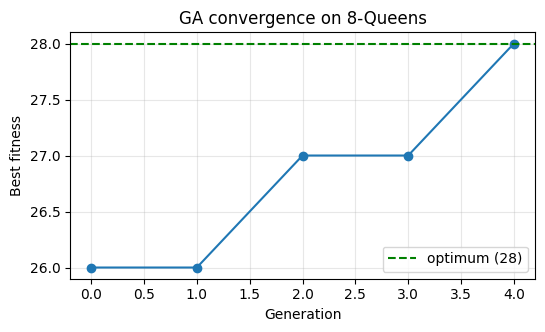

Over 100 runs: success 64 %, avg generations 410.4, avg evaluations 41139


In [10]:
def genetic(n=N, pop_size=100, max_gen=1000, pc=0.9, pm=0.2, elite=2, rng=random, history=False):
    max_f = n * (n - 1) // 2
    fit = lambda ch: max_f - conflicts(ch)
    pop = [[rng.randrange(n) for _ in range(n)] for _ in range(pop_size)]
    evals, hist = 0, []
    for gen in range(max_gen + 1):
        scored = sorted(((fit(c), c) for c in pop), key=lambda x: -x[0])
        evals += pop_size
        hist.append(scored[0][0])
        if scored[0][0] == max_f:
            return dict(state=scored[0][1], success=True, gen=gen, evals=evals, hist=hist)
        new = [c[:] for _, c in scored[:elite]]
        pick = lambda: max(rng.sample(scored, 3), key=lambda x: x[0])[1]
        while len(new) < pop_size:
            p1, p2 = pick(), pick()
            if rng.random() < pc:
                k = rng.randrange(1, n)
                child = p1[:k] + p2[k:]
            else:
                child = p1[:]
            if rng.random() < pm:
                child[rng.randrange(n)] = rng.randrange(n)
            new.append(child)
        pop = new
    return dict(state=scored[0][1], success=False, gen=max_gen, evals=evals, hist=hist)

rng = random.Random(7)
g = genetic(N, rng=rng)
print("Success        :", g['success'])
print("Generations    :", g['gen'])
print("Best chromosome:", g['state'], " conflicts:", conflicts(g['state']))
print("Fitness evals  :", g['evals'])
show_board(g['state'])

plt.figure(figsize=(6, 3.2))
plt.plot(g['hist'], marker='o')
plt.axhline(28, ls='--', c='g', label='optimum (28)')
plt.xlabel("Generation"); plt.ylabel("Best fitness"); plt.title("GA convergence on 8-Queens")
plt.legend(); plt.grid(alpha=.3); plt.show()

rng = random.Random(3)
res = [genetic(N, rng=rng) for _ in range(100)]
print("Over 100 runs: success %.0f %%, avg generations %.1f, avg evaluations %.0f" %
      (100*sum(x['success'] for x in res)/100, sum(x['gen'] for x in res)/100, sum(x['evals'] for x in res)/100))

**Output explanation:** The GA keeps a population of 100 boards. The best fitness rises quickly towards the optimum 28 as good partial arrangements are recombined by crossover and diversity is maintained by mutation. In these runs it solved only about two thirds of the 8-Queens boards within 1000 generations: with elitism and tournament selection the population often becomes too similar (premature convergence) and gets stuck one or two conflicts short of a solution. Because it also evaluates a whole population in every generation, it uses far more state evaluations and time than hill climbing with restarts. Results differ between runs because of the random operators, and tuning (larger mutation rate, bigger population, restarts) would improve the success rate.

# 4. CONSTRAINT SATISFACTION (CSP)

The CSP view exploits the *structure* of the problem: variables, domains and constraints are explicit, so the solver can **prune values before they cause a failure**.

* **Variables:** Q0 ... Q7 (queen of each row)
* **Domains:** {0..7} (column)
* **Constraints:** `Qi != Qj` and `|Qi - Qj| != |i - j|`

Four solvers are built on one generic backtracking engine:

| Solver | Idea |
|---|---|
| **BT** | Plain backtracking: assign variables in order, check against already assigned ones |
| **BT + FC** | **Forward checking**: after each assignment delete inconsistent values from the domains of unassigned variables; backtrack at once if a domain becomes empty |
| **BT + FC + MRV** | Choose next the variable with the **M**inimum **R**emaining **V**alues (fail-first) |
| **MAC (AC-3) + MRV** | **Maintain Arc Consistency**: run the AC-3 algorithm after every assignment for stronger pruning |

In [11]:
def csp_solve(n=N, fc=False, mrv=False, mac=False, find_all=False):
    t0 = time.perf_counter()
    stats = {'nodes': 0, 'backtracks': 0}
    solutions = []

    def consistent(i, a, j, b):
        return a != b and abs(a - b) != abs(i - j)

    def revise(doms, xi, xj):
        removed = False
        for a in list(doms[xi]):
            if not any(consistent(xi, a, xj, b) for b in doms[xj]):
                doms[xi].discard(a); removed = True
        return removed

    def ac3(doms, queue):
        while queue:
            xi, xj = queue.popleft()
            if revise(doms, xi, xj):
                if not doms[xi]:
                    return False
                for xk in range(n):
                    if xk != xi and xk != xj:
                        queue.append((xk, xi))
        return True

    def select_var(assign, doms):
        unassigned = [v for v in range(n) if v not in assign]
        if mrv:
            return min(unassigned, key=lambda v: (len(doms[v]), v))
        return unassigned[0]

    def bt(assign, doms):
        if len(assign) == n:
            solutions.append(tuple(assign[i] for i in range(n)))
            return not find_all
        v = select_var(assign, doms)
        for val in sorted(doms[v]):
            if not all(consistent(v, val, u, assign[u]) for u in assign):
                continue
            stats['nodes'] += 1
            if stats['nodes'] & 255 == 0: tick()
            assign[v] = val
            new, ok = doms, True
            if fc or mac:
                new = {k: set(s) for k, s in doms.items()}
                new[v] = {val}
                if mac:
                    ok = ac3(new, deque((u, v) for u in range(n) if u not in assign))
                else:
                    for u in range(n):
                        if u not in assign:
                            new[u] = {b for b in new[u] if consistent(u, b, v, val)}
                            if not new[u]:
                                ok = False; break
            if ok and bt(assign, new):
                return True
            del assign[v]
            stats['backtracks'] += 1
        return False

    bt({}, {i: set(range(n)) for i in range(n)})
    return pack(solutions[0] if solutions else None, stats['nodes'], n, t0,
                backtracks=stats['backtracks'], count=len(solutions))

csp_variants = {
    "Backtracking":         dict(),
    "BT + Forward Checking": dict(fc=True),
    "BT + FC + MRV":         dict(fc=True, mrv=True),
    "MAC (AC-3) + MRV":      dict(mac=True, mrv=True),
}

print("%-24s %-28s %8s %11s %10s" % ("Solver", "First solution", "Nodes", "Backtracks", "Time(ms)"))
for name, kw in csp_variants.items():
    r = run(csp_solve, **kw)
    print("%-24s %-28s %8d %11d %10.3f" % (name, r['solution'], r['nodes'], r['backtracks'], r['time'] * 1000))

print()
show_board(run(csp_solve, fc=True, mrv=True)['solution'])

Solver                   First solution                  Nodes  Backtracks   Time(ms)
Backtracking             (0, 4, 7, 5, 2, 6, 1, 3)          113         105      0.735
BT + Forward Checking    (0, 4, 7, 5, 2, 6, 1, 3)           88          80      0.460
BT + FC + MRV            (0, 4, 7, 5, 2, 6, 1, 3)           75          67      0.488
MAC (AC-3) + MRV         (0, 4, 7, 5, 2, 6, 1, 3)           20          12      1.279

Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


In [12]:
# Finding ALL solutions: the real test of search effort (8-Queens has exactly 92)
print("%-24s %10s %12s %12s %10s" % ("Solver", "Solutions", "Nodes", "Backtracks", "Time(ms)"))
for name, kw in csp_variants.items():
    r = run(csp_solve, find_all=True, **kw)
    print("%-24s %10d %12d %12d %10.2f" % (name, r['count'], r['nodes'], r['backtracks'], r['time'] * 1000))

Solver                    Solutions        Nodes   Backtracks   Time(ms)
Backtracking                     92         2056         2056      15.12
BT + Forward Checking            92         1724         1724       9.52
BT + FC + MRV                    92         1360         1360       9.07
MAC (AC-3) + MRV                 92          738          738      26.39


**Output explanation:** All four CSP solvers find the same (correct) solutions. Plain backtracking already prunes using the constraints, but it only discovers a dead end when it reaches it. **Forward checking** detects failures one step earlier by emptying a future domain, **MRV** attacks the most constrained variable first, and **MAC/AC-3** propagates the constraints furthest, giving the smallest search tree (fewest nodes and backtracks) at the cost of more work per node. The *all-solutions* run (92 solutions for N = 8) makes the differences in search effort clear.

# 5. PERFORMANCE EVALUATION

All algorithms are now run on the same problem and compared on:

* **Nodes / evaluations**: nodes expanded (tree and CSP search) or states evaluated (local search)
* **Peak memory**: largest number of states held at once (frontier, stack, population or recursion depth)
* **Time**: execution time (milliseconds)
* **Success**: whether a valid solution was found
* **Optimal**: whether the returned solution is guaranteed optimal (all N-Queens solutions cost N, so any valid answer is optimal in cost; the column states whether the *algorithm* guarantees it in general)
* **Complete**: whether the algorithm is guaranteed to find a solution when one exists

Deterministic algorithms are timed as the best of 5 runs. Randomised algorithms (hill climbing, GA) are averaged over 100 runs.

In [13]:
def best_time(fn, reps=5, **kw):
    r = run(fn, **kw)
    ts = [r['time']]
    for _ in range(reps - 1):
        ts.append(run(fn, **kw)['time'])
    r['time'] = min(ts)
    return r

rows = []
def add(cat, name, r, complete, optimal, succ="Yes"):
    rows.append(dict(Category=cat, Algorithm=name, Solved=succ, Nodes=round(r['nodes']), PeakMemory=r['peak'],
                     TimeMs=r['time'] * 1000, Complete=complete, Optimal=optimal))

add("Uninformed", "DFS",  best_time(dfs),  "No (infinite depth)", "No")
add("Uninformed", "BFS",  best_time(bfs),  "Yes", "Yes")
add("Uninformed", "DLS (limit=8)", best_time(dls, limit=8), "No (if limit too small)", "No")
add("Uninformed", "IDS",  best_time(ids),  "Yes", "Yes")
add("Informed",   "A*",   best_time(astar),  "Yes", "Yes (admissible h)")
add("Informed",   "Greedy Best-First", best_time(greedy), "No", "No")

# randomised algorithms: average over 100 runs
def avg_random(fn, runs=100, seed=11, **kw):
    rng = random.Random(seed)
    nodes = peak_t = 0; ok = 0; tt = 0
    for _ in range(runs):
        t0 = time.perf_counter()
        r = fn(N, rng=rng, **kw)
        tt += time.perf_counter() - t0
        nodes += r['evals']; ok += r['success']
    return dict(nodes=nodes / runs, time=tt / runs, ok=100 * ok / runs)

for name, fn, kw, mem in [("Hill Climbing (plain)", hill_climb, {}, 1),
                          ("Hill Climbing (sideways)", hill_climb, {'sideways': 100}, 1),
                          ("Hill Climbing (random restart)", hill_climb_restart, {}, 1),
                          ("Genetic Algorithm", genetic, {}, 100)]:
    a = avg_random(fn, **kw)
    rows.append(dict(Category="Local search", Algorithm=name, Solved="%.0f %% of runs" % a['ok'],
                     Nodes=round(a['nodes']), PeakMemory=mem, TimeMs=a['time'] * 1000,
                     Complete="No (probabilistic)" if 'restart' not in name else "Probabilistically yes",
                     Optimal="No"))

for name, kw in csp_variants.items():
    r = best_time(csp_solve, **kw)
    add("CSP", name, r, "Yes", "n/a (any solution)")

df = pd.DataFrame(rows)
df['TimeMs'] = df['TimeMs'].round(3)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
df

,Category,Algorithm,Solved,Nodes,PeakMemory,TimeMs,Complete,Optimal
0,Uninformed,DFS,Yes,114,19,0.353,No (infinite depth),No
1,Uninformed,BFS,Yes,1966,573,6.508,Yes,Yes
2,Uninformed,DLS (limit=8),Yes,114,9,0.327,No (if limit too small),No
3,Uninformed,IDS,Yes,5622,9,11.586,Yes,Yes
4,Informed,A*,Yes,54,17,1.798,Yes,Yes (admissible h)
5,Informed,Greedy Best-First,Yes,30,18,1.271,No,No
6,Local search,Hill Climbing (plain),14 % of runs,225,1,0.860,No (probabilistic),No
7,Local search,Hill Climbing (sideways),96 % of runs,1104,1,3.838,No (probabilistic),No
8,Local search,Hill Climbing (random restart),100 % of runs,1658,1,6.233,Probabilistically yes,No
9,Local search,Genetic Algorithm,66 % of runs,37836,100,331.542,No (probabilistic),No


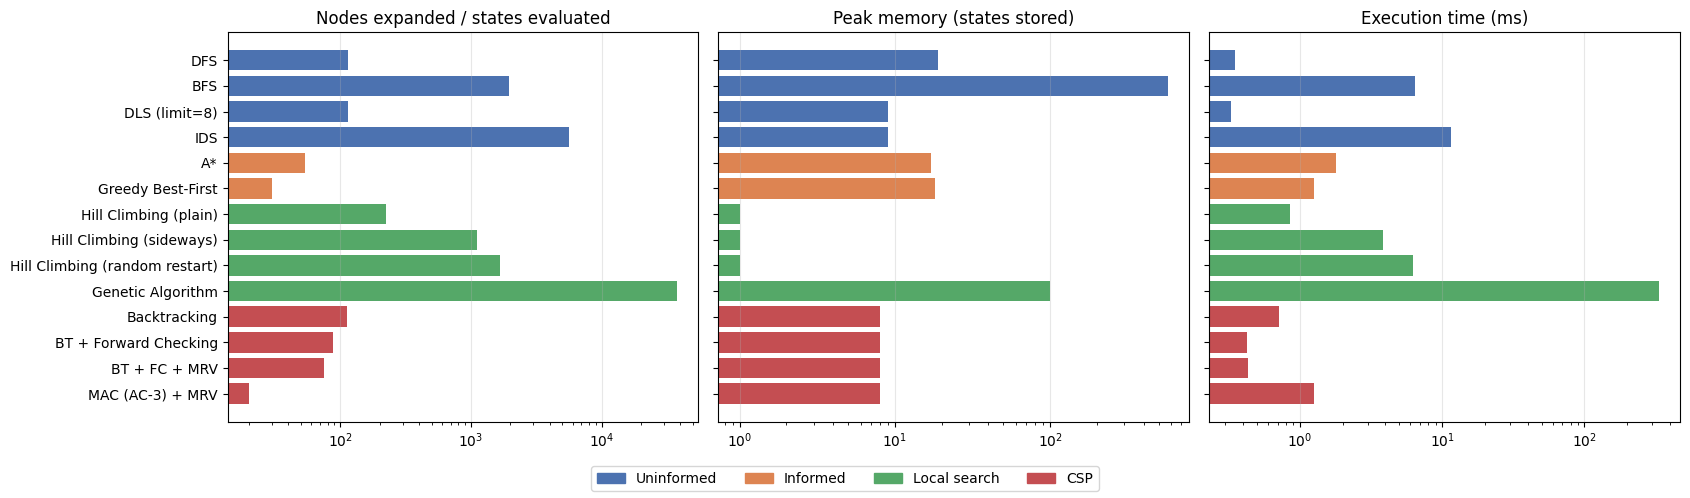

In [14]:
# ---------- bar charts: nodes and time ----------
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
colors = {"Uninformed": "#4c72b0", "Informed": "#dd8452", "Local search": "#55a868", "CSP": "#c44e52"}
c = [colors[x] for x in df['Category']]
y = range(len(df))
for a, col, title in zip(ax, ['Nodes', 'PeakMemory', 'TimeMs'],
                         ['Nodes expanded / states evaluated', 'Peak memory (states stored)', 'Execution time (ms)']):
    a.barh(list(y), df[col], color=c)
    a.set_yticks(list(y)); a.set_yticklabels(df['Algorithm'] if a is ax[0] else [])
    a.set_xscale('log'); a.set_title(title); a.invert_yaxis(); a.grid(axis='x', alpha=.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colors.values()]
fig.legend(handles, colors.keys(), loc='lower center', ncol=4)
plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()

## 5.1 Scalability: increasing the board size

8-Queens is small. To see how each family *scales*, the first solution is searched for N = 4, 6, 8, 10, 12, 14 with a **5 second limit** per run. A missing point means the algorithm ran out of time (or, for randomised ones, did not find a solution).

Execution time (ms)   [nan = timed out / not solved]


,N=4,N=6,N=8,N=10,N=12,N=14
BFS,0.05,0.52,9.19,170.31,4994.37,NaN
DFS,0.07,0.08,0.37,0.42,1.44,13.89
IDS,0.08,0.53,11.90,310.98,NaN,NaN
A*,0.09,0.38,1.82,3.17,9.80,85.19
Greedy,0.09,0.56,1.18,1.40,9.73,12.84
Hill Climb (restart),0.10,1.40,6.17,57.83,39.67,444.95
Genetic Algorithm,1.09,0.48,NaN,28.27,NaN,64.14
Backtracking,0.05,0.14,0.71,0.79,2.58,24.51
BT+FC+MRV,0.06,0.15,0.52,0.28,1.43,1.30
MAC+MRV,0.07,0.34,1.24,1.50,5.61,6.66


Nodes expanded / states evaluated


,N=4,N=6,N=8,N=10,N=12,N=14
BFS,16.0,150.0,1966.0,34816.0,841990.0,NaN
DFS,9.0,32.0,114.0,103.0,262.0,1900.0
IDS,41.0,388.0,5622.0,110107.0,NaN,NaN
A*,7.0,20.0,54.0,54.0,112.0,876.0
Greedy,7.0,27.0,30.0,11.0,134.0,100.0
Hill Climb (restart),50.0,637.0,1912.0,12720.0,6476.0,51731.0
Genetic Algorithm,200.0,100.0,NaN,2800.0,NaN,4800.0
Backtracking,8.0,31.0,113.0,102.0,261.0,1899.0
BT+FC+MRV,8.0,27.0,75.0,35.0,153.0,124.0
MAC+MRV,5.0,11.0,20.0,16.0,51.0,41.0


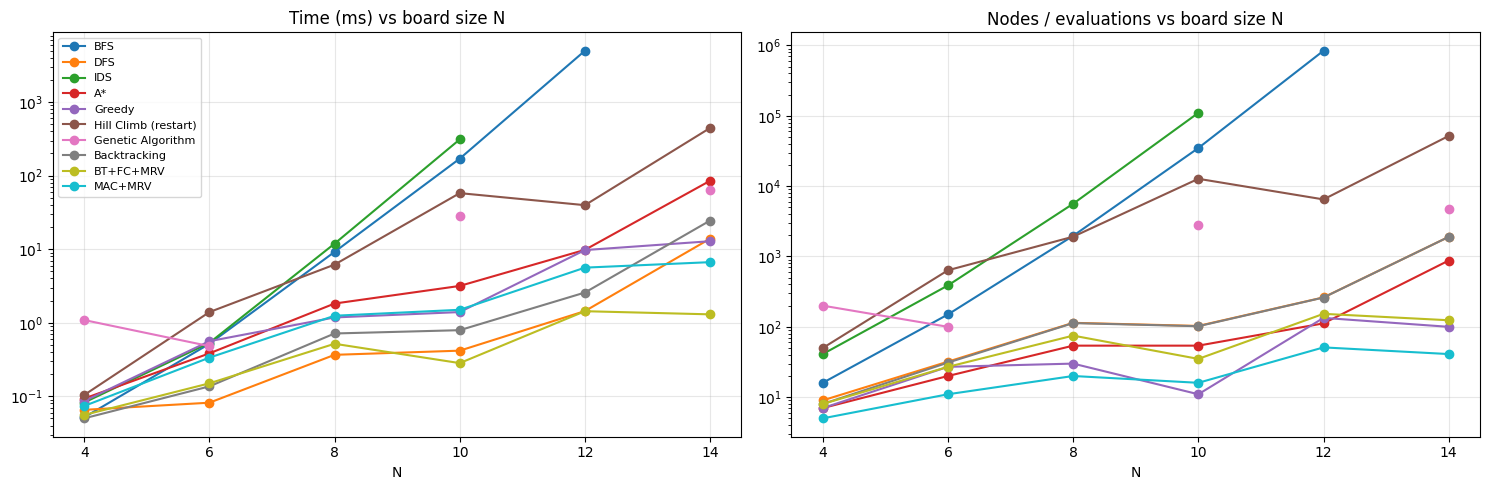

In [15]:
sizes = [4, 6, 8, 10, 12, 14]
TL = 5

def rand_wrapper(fn, **kw):
    def f(n):
        rng = random.Random(5)
        t0 = time.perf_counter()
        r = fn(n, rng=rng, **kw)
        return dict(solution=r['state'] if r['success'] else None, nodes=r['evals'], peak=1, time=time.perf_counter() - t0)
    return f

algos = {
    "BFS": bfs, "DFS": dfs, "IDS": ids, "A*": astar, "Greedy": greedy,
    "Hill Climb (restart)": rand_wrapper(hill_climb_restart),
    "Genetic Algorithm": rand_wrapper(genetic),
    "Backtracking": lambda n: csp_solve(n),
    "BT+FC+MRV": lambda n: csp_solve(n, fc=True, mrv=True),
    "MAC+MRV": lambda n: csp_solve(n, mac=True, mrv=True),
}

time_tab, node_tab = {}, {}
for name, fn in algos.items():
    ts, ns = [], []
    for n in sizes:
        r = run(fn, n=n, tl=TL)
        ok = r.get('solution') is not None
        ts.append(r['time'] * 1000 if ok else float('nan'))
        ns.append(r['nodes'] if ok else float('nan'))
    time_tab[name], node_tab[name] = ts, ns

print("Execution time (ms)   [nan = timed out / not solved]")
display(pd.DataFrame(time_tab, index=["N=%d" % s for s in sizes]).T.round(2))
print("Nodes expanded / states evaluated")
display(pd.DataFrame(node_tab, index=["N=%d" % s for s in sizes]).T)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name in algos:
    ax[0].plot(sizes, time_tab[name], marker='o', label=name)
    ax[1].plot(sizes, node_tab[name], marker='o', label=name)
for a, t in zip(ax, ["Time (ms) vs board size N", "Nodes / evaluations vs board size N"]):
    a.set_yscale('log'); a.set_xlabel("N"); a.set_title(t); a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5.2 Theoretical comparison

(b = branching factor, d = depth of the solution, m = maximum depth)

| Algorithm | Time | Space | Complete | Optimal |
|---|---|---|---|---|
| DFS | O(b^m) | O(bm) | No (infinite depth) | No |
| BFS | O(b^d) | O(b^d) | Yes | Yes (uniform cost) |
| DLS | O(b^l) | O(bl) | No (if l < d) | No |
| IDS | O(b^d) | O(bd) | Yes | Yes (uniform cost) |
| A\* | exponential, depends on h | exponential | Yes | Yes (admissible h) |
| Greedy Best-First | O(b^m) | O(b^m) | No | No |
| Hill Climbing | O(iterations x neighbours) | O(1) | No (local minima) | No |
| Genetic Algorithm | O(generations x population) | O(population) | No (probabilistic) | No |
| CSP Backtracking (+FC, MRV, AC-3) | O(d^n) worst case, far smaller in practice | O(n) | Yes | n/a (any solution is valid) |

# 6. CONCLUSION

All four families of search algorithms were implemented on the 8-Queens problem and evaluated on nodes expanded, memory, time, success and scalability.

**Uninformed search.** BFS and IDS are complete and optimal, but they are the most expensive: for N = 8, BFS expanded 1966 nodes and held up to 573 states in its queue, and IDS expanded 5622 nodes (re-expanding earlier levels) although it needed only 9 stored states. DFS (114 nodes, small stack) was much cheaper here because all solutions lie at the same depth and are plentiful, but it has no completeness/optimality guarantee in general. DLS is only correct if the limit is at least the solution depth (limits 6 and 7 returned a cutoff). On larger boards BFS and IDS ran out of the 5 s limit at N = 12.

**Informed search.** Using a heuristic plus dead-end detection greatly reduced the search effort: A\* expanded 54 nodes and Greedy Best-First only 30, compared with 1966 for BFS. A\* with the admissible heuristic h = N - k keeps the optimality guarantee; Greedy is the fastest by node count but gives no guarantee. Both kept scaling to N = 14.

**Local search.** Hill climbing needs almost no memory (one state) but is incomplete: plain steepest ascent solved only about 15 % of random boards, sideways moves raised this to about 95 %, and random restarts made it succeed in every run (about 6 restarts on average). The Genetic Algorithm solved only about two thirds of the runs within 1000 generations and used by far the most evaluations and time, so for this problem it is the least efficient method (it is better suited to problems without a good local-move structure).

**Constraint satisfaction.** Exploiting the constraint structure gave the best overall results. Backtracking took 113 nodes; forward checking cut it to 88, adding MRV to 75, and MAC (AC-3) to only 20. For finding all 92 solutions the nodes fell from 2056 (backtracking) to 738 (MAC). MAC does more work per node, so for a single 8-Queens solution its time is slightly higher than FC + MRV, but its advantage grows with problem size: BT + FC + MRV and MAC solved N = 14 in about 1 to 7 ms, while BFS and IDS could not solve N = 12 at all.

**Overall:** for a problem with explicit constraints like N-Queens, **CSP solvers (forward checking / MRV / AC-3) > informed search > DFS > hill climbing with restarts > BFS / IDS > Genetic Algorithm** in terms of efficiency. Uninformed BFS/IDS are guaranteed but do not scale, local search trades completeness for tiny memory, and the best method depends on whether a guarantee (completeness / optimality), speed, or memory is the priority.

*Note: node counts of the deterministic algorithms are exact and reproducible. Times depend on the machine, and the randomised algorithms (hill climbing, GA) vary between runs because of the random seed.*